# Step 6: EDA shortlist (exploratory)

**Purpose.** Screen six candidate comparisons between Normal and Return/Repair (RR) machines so that 3-4 can be taken forward. This is exploration: it reports what the data shows, does not explain causes, and every "so what" is a hypothesis.

**Rules used throughout**
- Reads only `data/model/`. Unit of analysis is the **machine**; cohorts are compared on machine-level medians (RR minus Normal).
- Interval = bootstrap 95% interval of the difference in medians (machines resampled within cohort, 2,000 resamples, fixed seed). Several comparisons are made here, so **no single interval is proof**; all results are exploratory.
- Robustness = "direction holds: yes/no" (same sign of the RR - Normal difference as the main result). The SV53-only check matters most: every RR machine with a known model is SV53, while Normal also contains SV50.
- RR is a selected population (machines that came back for return or repair), so differences are not evidence of cause.
- Colours: Normal = blue, Return/Repair = orange, in every chart.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import eda_helpers as h
h.style()
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 100)

t = h.load_model()
ms, dim, fs, ff = t['summary'], t['dim'], t['session'], t['fault']
elig = ms[ms.rate_eligible].copy()           # >= 10 analysis sessions
OUT_FAULT = 'flag_outlier_faults_per_100'
OUT_SPW = 'flag_outlier_sessions_per_week'
print(h.N_BOOT, 'resamples, seed', h.SEED)
SHORTLIST = []   # one dict per candidate metric; written to reports/eda/shortlist.md at the end

2000 resamples, seed 20261011


## Context: what is being compared
Cohort mix first, so the comparison base is visible before any result.

In [2]:
def mix(col):
    x = dim.assign(**{col: dim[col].fillna('(not available)')})
    return pd.crosstab(x[col], x.cohort.map(h.LABELS)).assign(Total=lambda d: d.sum(axis=1))

ctx_model, ctx_region, ctx_pack = mix('model'), mix('region'), mix('pack_type')
print('Machines by model'); display(ctx_model)
print('Machines by region'); display(ctx_region)
print('Machines by pack_type (known only for machines with battery data)'); display(ctx_pack)

Machines by model


cohort,Normal,Return/Repair,Total
model,,,
(not available),13,3,16
SV50-AA,12,0,12
SV50-AC,23,0,23
SV50-AF,70,0,70
SV53-AA,2,1,3
SV53-AB,21,24,45
SV53-AC,6,3,9
SV53-AE,5,3,8
SV53-AF,34,12,46


Machines by region


cohort,Normal,Return/Repair,Total
region,,,
(not available),13,2,15
CN-PROD,25,1,26
ROW-PPE,1,0,1
ROW-PROD,147,43,190


Machines by pack_type (known only for machines with battery data)


cohort,Normal,Return/Repair,Total
pack_type,,,
(not available),158,4,162
4-cell,18,0,18
7-cell,10,42,52


In [3]:
def nm(df, flag=None):
    d = df if flag is None else df[flag]
    return d.groupby('cohort').anonymized_serial.nunique().reindex([h.NORMAL, h.RR]).fillna(0).astype(int)

ctx_counts = pd.DataFrame({
    'All machines (dim_machine)': nm(dim),
    'fact_session (>=1 session)': nm(fs),
    'rate-eligible (>=10 sessions)': nm(elig),
    'fact_fault (>=1 fault occurrence)': nm(ff),
    'motor: >=1 analysis snapshot': nm(ms, ms.n_motor_snapshots > 0),
    'fact_motor_period (>=1 period)': nm(t['motor']),
    'fact_motor_period (>=1 valid period)': nm(t['motor'], t['motor'].delta_valid),
    'battery: >=1 analysis snapshot': nm(ms, ms.n_battery_snapshots > 0),
    'fact_battery_period (>=1 period)': nm(t['battery']),
    'all four tables': nm(ms, ms.has_all_four_tables),
}).T.rename(columns=h.LABELS)
ctx_counts['Total'] = ctx_counts.sum(axis=1)
display(ctx_counts)

sv = pd.DataFrame({
    'SV53 machines': ms[ms.model.fillna('').str.startswith('SV53')].groupby('cohort').size(),
    'SV50 machines': ms[ms.model.fillna('').str.startswith('SV50')].groupby('cohort').size(),
    'model unknown': ms[ms.model.isna()].groupby('cohort').size()}).fillna(0).astype(int).T.rename(columns=h.LABELS)
display(sv)
print('Rate-eligible machines with model SV53:', elig[elig.model.fillna('').str.startswith('SV53')].groupby('cohort').size().to_dict())

cohort,Normal,Return/Repair,Total
All machines (dim_machine),186,46,232
fact_session (>=1 session),173,43,216
rate-eligible (>=10 sessions),158,36,194
fact_fault (>=1 fault occurrence),143,33,176
motor: >=1 analysis snapshot,76,44,120
fact_motor_period (>=1 period),54,36,90
fact_motor_period (>=1 valid period),54,36,90
battery: >=1 analysis snapshot,28,42,70
fact_battery_period (>=1 period),25,36,61
all four tables,6,33,39


cohort,Normal,Return/Repair
SV53 machines,68,43
SV50 machines,105,0
model unknown,13,3


Rate-eligible machines with model SV53: {'normal': 59, 'return_repair': 36}


**Reading the base.** RR machines are all SV53 where the model is known (3 have no model); Normal is a mix of SV50 and SV53. Regions and pack types also differ (pack type is known only for machines with battery data, which is few for Normal). Only a handful of Normal machines are in the motor, battery or all-four-table samples, so those candidates have small Normal samples. Motor snapshots exist only for SV53 machines where the model is known (Normal motor machines are all SV53, 9 have no model), so motor candidates are already model-matched; battery snapshots include Normal SV50. These are the comparison conditions for everything below.

## Candidate 1: Fault rate

`faults_per_100_sessions_primary` per machine (zero-filled where a machine is not in the faults table, an **assumed** reading), machines with >= 10 analysis sessions. Primary counting rule (one row per serial + session + type + value + `fault_timestamp`).
Alternative rules: status rule (adds `fault_status` to the occurrence key) and fault-table machines only (no zero-fill).

,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,all eligible machines,158,36,6.53,9.69,3.15,1.48,-3.45,14.45,(reference)
1,SV53 only,59,36,1.11,9.69,8.58,8.72,2.92,18.89,yes
2,flagged outlier machines removed,151,33,5.56,7.81,2.26,1.41,-4.03,11.32,yes
3,status rule,158,36,10.67,15.50,4.84,1.45,-4.94,26.01,yes
4,fault-table machines only,137,32,10.64,14.95,4.31,1.40,-6.33,14.35,yes
5,SV53 + status rule,59,36,1.82,15.50,13.69,8.53,5.00,34.10,yes


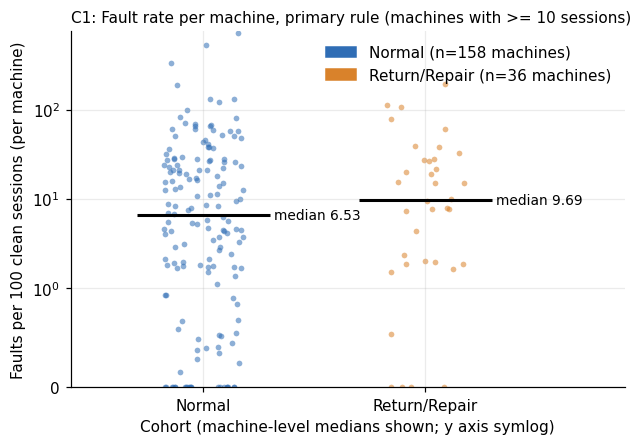

In [4]:
c1 = elig.copy()
col1 = 'faults_per_100_sessions_primary'
v1 = {
  'SV53 only': (h.sv53(c1), None),
  'flagged outlier machines removed': (c1[~c1[OUT_FAULT]], None),
  'status rule': (c1, 'faults_per_100_sessions_status_rule'),
  'fault-table machines only': (c1[c1.in_faults_table], 'faults_per_100_fault_machines_only_primary'),
  'SV53 + status rule': (h.sv53(c1), 'faults_per_100_sessions_status_rule'),
}
r1 = h.robustness(c1, col1, v1)
display(r1.round(2))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
h.strip_compare(ax, c1, col1, 'Faults per 100 clean sessions (per machine)',
                'C1: Fault rate per machine, primary rule (machines with >= 10 sessions)', log=True)
ax.set_xlabel('Cohort (machine-level medians shown; y axis symlog)')
f1 = h.save(fig, 'c1_fault_rate.png'); plt.show()

**Model-mix diagnostic (not a candidate).** The SV53-only result differs a lot from the all-machine result, so the Normal cohort is split by model family: SV50 vs SV53 among Normal machines (same method; the `normal` slot holds SV50 and the `rr` slot holds SV53 only to reuse the comparison function).

In [5]:
nrm = c1[c1.cohort == h.NORMAL].copy()
nrm['fam'] = nrm.model.str[:4]
d = nrm[nrm.fam.isin(['SV50', 'SV53'])].copy()
d['cohort'] = np.where(d.fam == 'SV53', h.RR, h.NORMAL)
diag = pd.DataFrame([h.compare(d, col1)]).rename(columns={'n_normal': 'n SV50', 'n_rr': 'n SV53', 'normal': 'SV50 median', 'rr': 'SV53 median', 'diff': 'SV53 - SV50', 'ratio': 'SV53 / SV50', 'ci_lo': 'ci_lo', 'ci_hi': 'ci_hi'})
display(diag.round(2))

,n SV50,n SV53,SV50 median,SV53 median,SV53 - SV50,SV53 / SV50,ci_lo,ci_hi
0,99,59,16.77,1.11,-15.66,0.07,-20.56,-10.73


In [6]:
SHORTLIST.append(dict(id='C1', name='Fault rate', metric='Faults per 100 clean sessions, per machine (median); primary rule, zero-filled',
  table=r1, chart=f1.name, extra=diag.round(2), extra_title='Model-mix diagnostic within Normal (faults per 100 sessions, median per machine; SV50 vs SV53):',
  trust='Session and fault counts: stated. Fault types present are 11/12/13 with brief meanings. Treating absence from the faults table as zero faults is assumed. Filter Wash (13) "needs cleaning" is counted as a fault; whether it is a failure is not stated.',
  risks='Selected population; model mix (SV50 only in Normal); fault timestamps and session dates are on different clocks (server date trails by hours to weeks); fault rows dominated by one type (see C2); medians change with the counting rule.',
  sowhat='Hypothesis (reliability): if RR machines raise faults more often per session, a fault-rate threshold could be tested as a screening signal for return risk.'))

## Candidate 2: Fault mix

Per fault type/value with a stated brief meaning: % of rate-eligible machines with >= 1 occurrence (difference in shares, bootstrap) and the pooled rate per 100 sessions (sum of faults / sum of sessions, bootstrap by machine). Medians are shown too but are 0 for most types, so they are not informative here. Only the type/value pairs present in the model appear (no type 7, no value 0, no 12/3).

In [7]:
combos = (ff.groupby(['fault_type', 'fault_value', 'fault_meaning']).size().reset_index(name='n_all'))
display(combos)
cnt = ff.groupby(['anonymized_serial', 'fault_type', 'fault_value']).agg(n_primary=('fault_key', 'size'), n_status=('n_status_rows', 'sum')).reset_index()

c2 = elig[['anonymized_serial', 'cohort', 'model', 'n_sessions', OUT_FAULT]].copy()
for _, r in combos.iterrows():
    k = 't%d_v%d' % (r.fault_type, r.fault_value)
    sub = cnt[(cnt.fault_type == r.fault_type) & (cnt.fault_value == r.fault_value)].set_index('anonymized_serial')
    c2['n_' + k] = c2.anonymized_serial.map(sub.n_primary).fillna(0)
    c2['ns_' + k] = c2.anonymized_serial.map(sub.n_status).fillna(0)
    c2['any_' + k] = (c2['n_' + k] > 0).astype(float)
    c2['rate_' + k] = 100.0 * c2['n_' + k] / c2.n_sessions
# consistency: totals equal machine_summary
chk = c2.merge(elig[['anonymized_serial', 'n_faults_primary', 'n_faults_status_rule']], on='anonymized_serial')
tot_p = chk[[c for c in chk.columns if c.startswith('n_t')]].sum(axis=1)
tot_s = chk[[c for c in chk.columns if c.startswith('ns_t')]].sum(axis=1)
print('type/value counts sum to machine_summary totals:', bool((tot_p == chk.n_faults_primary).all()), bool((tot_s == chk.n_faults_status_rule).all()))

,fault_type,fault_value,fault_meaning,n_all
0,11,2,Battery Temperature: HOT,1
1,12,1,"Airway Blockage: inlet blocked, motor still ru...",1189
2,12,2,Airway Blockage: inlet blocked and in error,719
3,13,1,Filter Wash: needs cleaning,2626


type/value counts sum to machine_summary totals: True True


In [8]:
rows, c2tabs = [], {}
for _, r in combos.iterrows():
    k = 't%d_v%d' % (r.fault_type, r.fault_value)
    label = '%d/%d %s' % (r.fault_type, r.fault_value, r.fault_meaning)
    v = {'SV53 only': (h.sv53(c2), None), 'flagged outliers removed': (c2[~c2[OUT_FAULT]], None)}
    share = h.robustness(c2, 'any_' + k, v, stat='mean')
    share.insert(0, 'measure', '% machines with >=1 (share)')
    pooled = []
    for lab, d in [('all eligible machines', c2), ('SV53 only', h.sv53(c2)), ('flagged outliers removed', c2[~c2[OUT_FAULT]])]:
        p = h.compare_pooled(d, 'n_' + k, 'n_sessions'); p['variant'] = lab; pooled.append(p)
    p = h.compare_pooled(c2, 'ns_' + k, 'n_sessions'); p['variant'] = 'status rule (all eligible)'; pooled.append(p)
    p = h.compare_pooled(h.sv53(c2), 'ns_' + k, 'n_sessions'); p['variant'] = 'SV53 + status rule'; pooled.append(p)
    pooled = pd.DataFrame(pooled)
    ref = pooled.iloc[0]['diff']
    pooled['direction_holds'] = ['(reference)'] + [h.direction_holds(ref, x) for x in pooled['diff'][1:]]
    pooled.insert(0, 'measure', 'pooled faults per 100 sessions')
    med = h.compare(c2, 'rate_' + k)
    tab = pd.concat([share, pooled[share.columns]], ignore_index=True)
    c2tabs[label] = (tab, med, int(r.n_all))
    print('\n###', label, '(all occurrences in model: %d); median per-machine rate: Normal %.2f, RR %.2f' % (r.n_all, med['normal'], med['rr']))
    display(tab.round(3))


### 11/2 Battery Temperature: HOT (all occurrences in model: 1); median per-machine rate: Normal 0.00, RR 0.00


,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,% machines with >=1 (share),all eligible machines,158,36,0.006,0.0,-0.006,0.0,-0.019,0.0,(reference)
1,% machines with >=1 (share),SV53 only,59,36,0.000,0.0,0.000,NaN,0.000,0.0,n/a
2,% machines with >=1 (share),flagged outliers removed,151,33,0.007,0.0,-0.007,0.0,-0.020,0.0,yes
3,pooled faults per 100 sessions,all eligible machines,158,36,0.003,0.0,-0.003,0.0,-0.011,0.0,(reference)
4,pooled faults per 100 sessions,SV53 only,59,36,0.000,0.0,0.000,NaN,0.000,0.0,n/a
5,pooled faults per 100 sessions,flagged outliers removed,151,33,0.003,0.0,-0.003,0.0,-0.011,0.0,yes
6,pooled faults per 100 sessions,status rule (all eligible),158,36,0.003,0.0,-0.003,0.0,-0.011,0.0,yes
7,pooled faults per 100 sessions,SV53 + status rule,59,36,0.000,0.0,0.000,NaN,0.000,0.0,n/a



### 12/1 Airway Blockage: inlet blocked, motor still running (all occurrences in model: 1189); median per-machine rate: Normal 1.02, RR 0.27


,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,% machines with >=1 (share),all eligible machines,158,36,0.614,0.500,-0.114,0.814,-0.291,0.063,(reference)
1,% machines with >=1 (share),SV53 only,59,36,0.356,0.500,0.144,1.405,-0.063,0.340,no
2,% machines with >=1 (share),flagged outliers removed,151,33,0.596,0.485,-0.111,0.813,-0.296,0.083,yes
3,pooled faults per 100 sessions,all eligible machines,158,36,2.877,6.588,3.712,2.290,-1.433,12.334,(reference)
4,pooled faults per 100 sessions,SV53 only,59,36,1.706,6.588,4.883,3.862,-0.805,13.566,yes
5,pooled faults per 100 sessions,flagged outliers removed,151,33,2.254,2.862,0.608,1.270,-1.253,3.129,yes
6,pooled faults per 100 sessions,status rule (all eligible),158,36,3.598,9.002,5.404,2.502,-0.816,14.732,yes
7,pooled faults per 100 sessions,SV53 + status rule,59,36,1.954,9.002,7.048,4.606,0.498,16.224,yes



### 12/2 Airway Blockage: inlet blocked and in error (all occurrences in model: 719); median per-machine rate: Normal 0.07, RR 1.53


,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,% machines with >=1 (share),all eligible machines,158,36,0.500,0.611,0.111,1.222,-0.078,0.275,(reference)
1,% machines with >=1 (share),SV53 only,59,36,0.475,0.611,0.137,1.288,-0.072,0.332,yes
2,% machines with >=1 (share),flagged outliers removed,151,33,0.483,0.576,0.092,1.191,-0.105,0.281,yes
3,pooled faults per 100 sessions,all eligible machines,158,36,1.349,6.501,5.152,4.820,1.249,11.654,(reference)
4,pooled faults per 100 sessions,SV53 only,59,36,1.106,6.501,5.396,5.879,1.484,11.482,yes
5,pooled faults per 100 sessions,flagged outliers removed,151,33,1.042,3.938,2.896,3.780,0.859,6.335,yes
6,pooled faults per 100 sessions,status rule (all eligible),158,36,1.661,9.067,7.406,5.459,2.652,14.905,yes
7,pooled faults per 100 sessions,SV53 + status rule,59,36,1.449,9.067,7.619,6.259,2.774,14.701,yes



### 13/1 Filter Wash: needs cleaning (all occurrences in model: 2626); median per-machine rate: Normal 2.29, RR 0.12


,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,% machines with >=1 (share),all eligible machines,158,36,0.696,0.500,-0.196,0.718,-0.376,-0.019,(reference)
1,% machines with >=1 (share),SV53 only,59,36,0.424,0.500,0.076,1.180,-0.126,0.277,no
2,% machines with >=1 (share),flagged outliers removed,151,33,0.689,0.485,-0.204,0.704,-0.389,-0.022,yes
3,pooled faults per 100 sessions,all eligible machines,158,36,7.661,5.588,-2.073,0.729,-6.263,3.980,(reference)
4,pooled faults per 100 sessions,SV53 only,59,36,1.474,5.588,4.114,3.790,0.176,9.744,no
5,pooled faults per 100 sessions,flagged outliers removed,151,33,7.050,3.297,-3.754,0.468,-6.350,-1.047,yes
6,pooled faults per 100 sessions,status rule (all eligible),158,36,8.201,7.349,-0.851,0.896,-5.635,5.798,yes
7,pooled faults per 100 sessions,SV53 + status rule,59,36,1.749,7.349,5.601,4.203,0.903,11.550,no


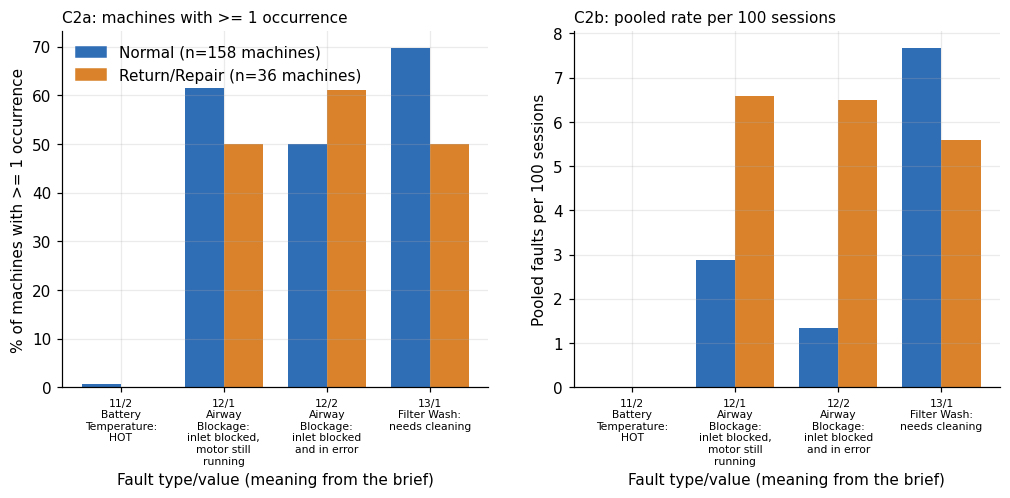

In [9]:
# chart: share of machines with >= 1 occurrence, and pooled rate, per type/value
labs = list(c2tabs)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(len(labs)); w = 0.38
ns = {h.NORMAL: int((c2.cohort == h.NORMAL).sum()), h.RR: int((c2.cohort == h.RR).sum())}
for ax, meas, ylab, scale in [(axes[0], '% machines with >=1 (share)', '% of machines with >= 1 occurrence', 100),
                              (axes[1], 'pooled faults per 100 sessions', 'Pooled faults per 100 sessions', 1)]:
    for j, c in enumerate((h.NORMAL, h.RR)):
        vals = []
        for lab in labs:
            tab = c2tabs[lab][0]
            row = tab[(tab.measure == meas)].iloc[0]
            vals.append(scale * (row.normal if c == h.NORMAL else row.rr))
        ax.bar(x + (j - 0.5) * w, vals, w, color=h.COLORS[c])
    import textwrap
    ax.set_xticks(x); ax.set_xticklabels([l.split(' ', 1)[0] + '\n' + textwrap.fill(l.split(' ', 1)[1], 14) for l in labs], fontsize=7)
    ax.set_ylabel(ylab); ax.set_xlabel('Fault type/value (meaning from the brief)')
axes[0].set_title('C2a: machines with >= 1 occurrence', fontsize=10, loc='left')
axes[1].set_title('C2b: pooled rate per 100 sessions', fontsize=10, loc='left')
h._legend(axes[0], ns, loc='upper left')
f2 = h.save(fig, 'c2_fault_mix.png'); plt.show()

In [10]:
for lab, (tab, med, n_all) in c2tabs.items():
    nr = lab.startswith('12/1') or lab.startswith('13/1')
    SHORTLIST.append(dict(id='C2', name='Fault mix: ' + lab + (' [maintenance alert, our grouping]' if lab.startswith('13/1') else ''), metric='% machines with >=1 occurrence (rate-eligible machines); pooled faults per 100 sessions',
      table=tab, chart=f2.name, n_occ=n_all, med=med,
      trust='Fault type/value meaning: stated in the brief. Rates: same assumptions as C1.',
      risks='Only 4 type/value pairs exist in the model; 11/2 has a single occurrence. Medians are mostly 0. Same selection, model-mix and clock risks as C1.',
      sowhat=('CHECKED, NOT ROBUST (direction flips under SV53-only); not a finding.' if nr else 'Hypothesis (product/reliability): the cohort gap, if any, is concentrated in particular fault types, which would point to specific subsystems.')))

## Candidate 3: Motor load (share of runtime at 300-400 W)

Share of motor runtime in the 300-400 W power band, per machine, two ways: **lifetime** (latest analysis snapshot: band seconds / `runtime_s`) and **observed window** (valid snapshot periods only). Lifetime is the main version. Machines need >= 1 hour of lifetime runtime (my choice, to avoid shares from a few seconds of data); the no-minimum version is a robustness check. The power-band unit (W) is stated in the bin JSON; **what drives time in this band is not stated anywhere.** For RR, `runtime_s = sum(PowerBins)` is assumed.

In [11]:
c3 = ms[(ms.n_motor_snapshots > 0) & ms.share_runtime_300_400w_lifetime.notna()].copy()
c3_min = c3[c3.motor_latest_runtime_s >= 3600]
col3 = 'share_runtime_300_400w_lifetime'
v3 = {
  'SV53 only': (h.sv53(c3_min), None),
  'flagged outliers removed (either flag)': (c3_min[~(c3_min[OUT_FAULT] | c3_min[OUT_SPW])], None),
  'observed window (valid periods) share': (c3_min, 'share_runtime_300_400w_valid_periods'),
  'no minimum runtime': (c3, None),
  'SV53 + observed window': (h.sv53(c3_min), 'share_runtime_300_400w_valid_periods'),
}
r3 = h.robustness(c3_min, col3, v3, main_label='lifetime share, >= 1 h runtime')
display(r3.round(3))
print('Machines with a motor snapshot but excluded for runtime < 1 h:', c3.groupby('cohort').size().sub(c3_min.groupby('cohort').size()).to_dict())

band_cols = [c for c in ms.columns if c.startswith('share_runtime_power_')]
prof = []
for bc in band_cols:
    r = h.compare(c3_min, bc)
    r['band'] = bc.replace('share_runtime_power_', '').replace('_', '-').replace('lt-', '<').replace('gt-', '>') + ' W'
    prof.append(r)
prof = pd.DataFrame(prof)[['band', 'n_normal', 'n_rr', 'normal', 'rr', 'diff', 'ci_lo', 'ci_hi']]
display(prof.round(3))
print('Sum of median shares (medians need not add to 1): Normal %.2f, RR %.2f' % (prof.normal.sum(), prof.rr.sum()))

,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,"lifetime share, >= 1 h runtime",51,37,0.061,0.064,0.003,1.045,-0.027,0.134,(reference)
1,SV53 only,51,36,0.061,0.068,0.007,1.110,-0.023,0.145,yes
2,flagged outliers removed (either flag),50,32,0.061,0.068,0.007,1.121,-0.029,0.165,yes
3,observed window (valid periods) share,50,34,0.059,0.070,0.011,1.188,-0.023,0.143,yes
4,no minimum runtime,76,44,0.061,0.067,0.006,1.105,-0.023,0.106,yes
5,SV53 + observed window,50,34,0.059,0.070,0.011,1.188,-0.023,0.143,yes


Machines with a motor snapshot but excluded for runtime < 1 h: {'normal': 25, 'return_repair': 7}


,band,n_normal,n_rr,normal,rr,diff,ci_lo,ci_hi
0,<50 W,51,37,0.000,0.000,-0.000,-0.000,0.000
1,50-75 W,51,37,0.015,0.026,0.011,-0.013,0.033
2,75-100 W,51,37,0.298,0.241,-0.057,-0.128,0.033
3,100-125 W,51,37,0.277,0.237,-0.040,-0.101,0.077
4,125-150 W,51,37,0.039,0.046,0.007,-0.019,0.045
5,150-200 W,51,37,0.114,0.111,-0.003,-0.048,0.040
6,200-300 W,51,37,0.040,0.019,-0.021,-0.054,-0.002
7,300-400 W,51,37,0.061,0.064,0.003,-0.027,0.134
8,400-500 W,51,37,0.015,0.004,-0.011,-0.019,0.000
9,500-600 W,51,37,0.000,0.000,0.000,0.000,0.000


Sum of median shares (medians need not add to 1): Normal 0.86, RR 0.75


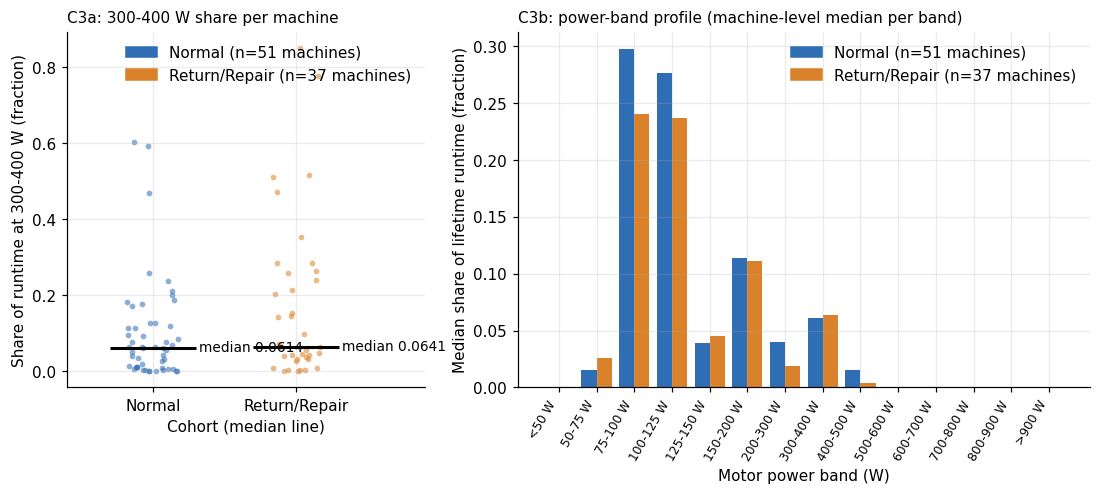

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
h.strip_compare(axes[0], c3_min, col3, 'Share of runtime at 300-400 W (fraction)',
                'C3a: 300-400 W share per machine', log=False)
axes[0].set_xlabel('Cohort (median line)')
x = np.arange(len(prof)); w = 0.4
for j, c in enumerate((h.NORMAL, h.RR)):
    axes[1].bar(x + (j - 0.5) * w, prof['normal' if c == h.NORMAL else 'rr'], w, color=h.COLORS[c])
axes[1].set_xticks(x); axes[1].set_xticklabels(prof.band, rotation=60, ha='right', fontsize=8)
axes[1].set_ylabel('Median share of lifetime runtime (fraction)'); axes[1].set_xlabel('Motor power band (W)')
axes[1].set_title('C3b: power-band profile (machine-level median per band)', fontsize=10, loc='left')
h._legend(axes[1], {h.NORMAL: int((c3_min.cohort == h.NORMAL).sum()), h.RR: int((c3_min.cohort == h.RR).sum())}, loc='upper right')
f3 = h.save(fig, 'c3_motor_load.png'); plt.show()

In [13]:
SHORTLIST.append(dict(id='C3', name='Motor load', metric='Share of lifetime runtime at 300-400 W, per machine (median)',
  table=r3, chart=f3.name, extra=prof, extra_title='Power-band profile (machine-level median share of lifetime runtime per band):',
  trust='Power-band edges and unit (W) and runtime in seconds: stated (bin JSON). What determines time in 300-400 W: not stated. RR runtime = sum of power bins: assumed (verified for Normal).',
  risks='Small Normal motor sample; model known for only some motor machines (SV53-only n is small); lifetime shares include time before observation; selected population.',
  sowhat='Hypothesis (engineering): a different load profile in RR machines may reflect operating conditions or component state; needs the driver of the band before any claim.'))

## Candidate 4: Usage intensity

Three metrics per machine: sessions per week (machines with >= 10 sessions; Step 5 definition, 1-week floor on the span), median `clean_duration` (**unit not stated**; machines with >= 10 valid durations), and motor runtime per day (valid periods only; minutes/day = seconds/day / 60; machines with >= 1 valid period). Alternative for motor: >= 28 valid days observed.

In [14]:
c4a = elig.copy()
c4b = ms[ms.n_duration_valid >= 10].copy()
c4c = ms[ms.motor_runtime_s_per_day.notna()].copy()
c4c['motor_min_per_day'] = c4c.motor_runtime_s_per_day / 60.0

v4a = {'SV53 only': (h.sv53(c4a), None),
       'flagged outliers removed (sessions-per-week flag)': (c4a[~c4a[OUT_SPW]], None)}
v4b = {'SV53 only': (h.sv53(c4b), None),
       'flagged outliers removed (either flag)': (c4b[~(c4b[OUT_FAULT] | c4b[OUT_SPW])], None)}
v4c = {'SV53 only': (h.sv53(c4c), None),
       'flagged outliers removed (either flag)': (c4c[~(c4c[OUT_FAULT] | c4c[OUT_SPW])], None),
       '>= 28 valid days observed': (c4c[c4c.motor_valid_days >= 28], None)}
r4a = h.robustness(c4a, 'sessions_per_week', v4a)
r4b = h.robustness(c4b, 'median_clean_duration', v4b)
r4c = h.robustness(c4c, 'motor_min_per_day', v4c)
for nme, r in [('Sessions per week', r4a), ('Median clean_duration (unit not stated)', r4b), ('Motor runtime minutes/day', r4c)]:
    print('###', nme); display(r.round(3))

### Sessions per week


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,all eligible machines,158,36,6.819,8.101,1.282,1.188,-2.067,4.132,(reference)
1,SV53 only,59,36,6.547,8.101,1.554,1.237,-1.897,4.538,yes
2,flagged outliers removed (sessions-per-week flag),150,34,6.355,7.620,1.265,1.199,-1.660,4.130,yes


### Median clean_duration (unit not stated)


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,all eligible machines,156,36,179.25,217.0,37.75,1.211,5.750,104.000,(reference)
1,SV53 only,59,36,164.00,217.0,53.00,1.323,12.488,109.006,yes
2,flagged outliers removed (either flag),142,31,180.00,214.5,34.50,1.192,-2.500,104.500,yes


### Motor runtime minutes/day


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,all eligible machines,54,36,2.384,4.869,2.485,2.042,0.430,3.979,(reference)
1,SV53 only,54,36,2.384,4.869,2.485,2.042,0.430,3.979,yes
2,flagged outliers removed (either flag),53,31,2.315,4.201,1.886,1.815,-0.051,3.444,yes
3,>= 28 valid days observed,54,31,2.384,4.223,1.839,1.771,0.261,3.719,yes


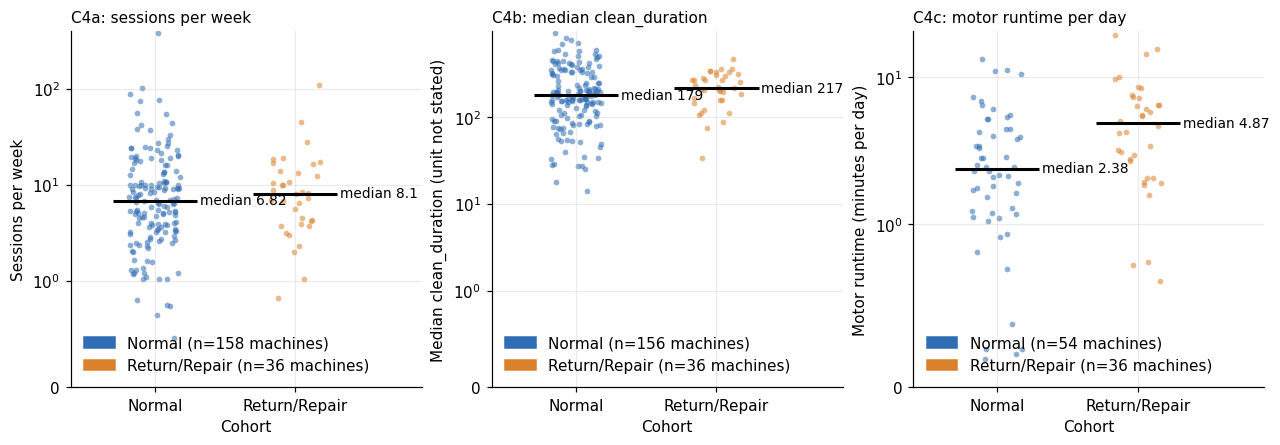

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
h.strip_compare(axes[0], c4a, 'sessions_per_week', 'Sessions per week', 'C4a: sessions per week', log=True)
h.strip_compare(axes[1], c4b, 'median_clean_duration', 'Median clean_duration (unit not stated)', 'C4b: median clean_duration', log=True)
h.strip_compare(axes[2], c4c, 'motor_min_per_day', 'Motor runtime (minutes per day)', 'C4c: motor runtime per day', log=True)
for a in axes: a.set_xlabel('Cohort')
f4 = h.save(fig, 'c4_usage_intensity.png'); plt.show()

In [16]:
trust4 = 'Sessions and runtime (seconds): stated. `clean_duration` unit: not stated. Sessions per week uses server-side `date_server` (inferred) and a 1-week span floor (assumed).'
risk4 = 'Selected population; observation windows differ in length by cohort; model mix; motor sample small for Normal.'
for sid, nme, r, so in [('C4a', 'Usage: sessions per week', r4a, 'Hypothesis (product): if RR machines are used more per week, wear-related causes become plausible and usage-normalised targets are needed.'),
                        ('C4b', 'Usage: median clean_duration', r4b, 'Hypothesis (product): duration differences would need the unit and meaning of clean_duration before use.'),
                        ('C4c', 'Usage: motor runtime per day', r4c, 'Hypothesis (engineering): runtime per day gives an exposure measure for normalising faults.')]:
    SHORTLIST.append(dict(id=sid, name=nme, metric=nme + ' (median per machine)', table=r, chart=f4.name, trust=trust4, risks=risk4, sowhat=so))

## Candidate 5: Battery (SV53-only is the main comparison)

Median `battery_used` per session (start minus end charge; unit not stated, values 0-100) and median `battery_health` per machine (a battery health score per the brief), both from clean sessions, machines with >= 10 valid values. **Main comparison is SV53 only** because every RR machine with a known model is SV53. Temperature flags, dust columns and battery snapshot units are not used.

In [17]:
bh = (fs.dropna(subset=['battery_health_clean']).groupby('anonymized_serial')
        .battery_health_clean.agg(median_battery_health='median', n_health_valid='size'))
c5 = ms.join(bh, on='anonymized_serial')
c5a = c5[c5.n_battery_used_valid >= 10]
c5b = c5[c5.n_health_valid >= 10]

def r5(df, col):
    s = h.sv53(df)
    v = {'all models': (df, None),
         'SV53, flagged outliers removed (either flag)': (s[~(s[OUT_FAULT] | s[OUT_SPW])], None)}
    return h.robustness(s, col, v, main_label='SV53 only (main)')
r5a = r5(c5a, 'median_battery_used')
r5b = r5(c5b, 'median_battery_health')
print('### Median battery_used per session'); display(r5a.round(3))
print('### Median battery_health per machine'); display(r5b.round(3))

### Median battery_used per session


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,SV53 only (main),59,36,5.0,10.0,5.0,2.0,0.0,5.0,(reference)
1,all models,158,36,10.0,10.0,0.0,1.0,-5.0,5.0,n/a
2,"SV53, flagged outliers removed (either flag)",58,31,5.0,10.0,5.0,2.0,0.0,5.0,yes


### Median battery_health per machine


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,SV53 only (main),59,36,99.0,99.0,0.0,1.00,0.0,1.0,(reference)
1,all models,158,36,98.0,99.0,1.0,1.01,0.0,2.0,n/a
2,"SV53, flagged outliers removed (either flag)",58,31,99.0,99.0,0.0,1.00,0.0,1.0,n/a


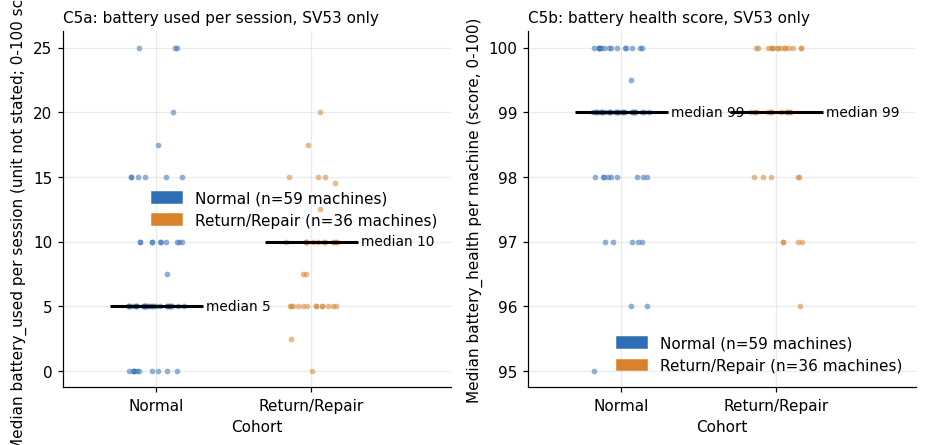

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
h.strip_compare(axes[0], h.sv53(c5a), 'median_battery_used', 'Median battery_used per session (unit not stated; 0-100 scale)', 'C5a: battery used per session, SV53 only')
h.strip_compare(axes[1], h.sv53(c5b), 'median_battery_health', 'Median battery_health per machine (score, 0-100)', 'C5b: battery health score, SV53 only')
for a in axes: a.set_xlabel('Cohort')
f5 = h.save(fig, 'c5_battery.png'); plt.show()

In [19]:
trust5 = 'battery_health: described in the brief as a battery health score (scale 0-100 checked in DQ). battery_used = start minus end charge, derived; unit not stated. Temperature, dust and snapshot units not used.'
risk5 = 'Selected population; pack type (capacity) unknown for most Normal machines; health score may drift with machine age/time, and observation windows differ; many health values are near 100 (little spread).'
SHORTLIST.append(dict(id='C5a', name='Battery: battery_used per session', metric='Median battery_used per session, per machine; SV53 only (median)', table=r5a, chart=f5.name, trust=trust5, risks=risk5,
  sowhat='Hypothesis (product): if RR machines drain more charge per session at equal model, battery sizing or usage patterns are worth checking.'))
SHORTLIST.append(dict(id='C5b', name='Battery: battery_health', metric='Median battery_health per machine; SV53 only (median)', table=r5b, chart=f5.name, trust=trust5, risks=risk5,
  sowhat='Hypothesis (reliability): a lower health score in RR machines would support a battery-related screening signal.'))

## Candidate 6: Warning signs before the data ends (exploratory)

For each machine: faults per 100 sessions in its **last 28 days of session data** (window ends at the machine's last `date_server`) versus all **earlier** data; both windows need >= 5 sessions. The metric is the change (last 28 days minus earlier). **The return date is not known; the end of a machine's data is only a proxy** for it. End-of-record effects (for example upload lag, or sessions logged but not yet joined to faults) apply to both cohorts, so the comparison is RR vs Normal, not the change alone.
Faults are placed in a window by `fault_timestamp` (main). Alternatives: (i) by the linked session's `date_server`, to share the sessions' clock; (ii) only machines whose data ends >= 28 days before the global last date, so the end of data is not simply the end of collection.

In [20]:
W = pd.Timedelta(days=28)
s6 = fs[['anonymized_serial', 'session_key', 'date_server']].copy()
last = s6.groupby('anonymized_serial').date_server.max().rename('last_ts')
s6 = s6.join(last, on='anonymized_serial')
s6['late'] = s6.date_server > s6.last_ts - W
ns6 = s6.groupby(['anonymized_serial', 'late']).size().unstack(fill_value=0).rename(columns={True: 'n_late', False: 'n_early'})

f6 = ff[['anonymized_serial', 'session_key', 'fault_timestamp']].join(last, on='anonymized_serial')
f6 = f6.merge(fs[['session_key', 'date_server']], on='session_key', how='left')
f6['late_ts'] = f6.fault_timestamp > f6.last_ts - W
f6['t_alt'] = f6.date_server.fillna(f6.fault_timestamp)
f6['late_alt'] = f6.t_alt > f6.last_ts - W
nf = pd.DataFrame({'f_late': f6.groupby('anonymized_serial').late_ts.sum(),
                   'f_early': f6.groupby('anonymized_serial').late_ts.apply(lambda x: (~x).sum()),
                   'fa_late': f6.groupby('anonymized_serial').late_alt.sum(),
                   'fa_early': f6.groupby('anonymized_serial').late_alt.apply(lambda x: (~x).sum())})
c6 = ms[['anonymized_serial', 'cohort', 'model', OUT_FAULT, OUT_SPW]].join(ns6, on='anonymized_serial').join(nf, on='anonymized_serial').join(last, on='anonymized_serial')
c6[['f_late', 'f_early', 'fa_late', 'fa_early']] = c6[['f_late', 'f_early', 'fa_late', 'fa_early']].fillna(0)
c6 = c6[(c6.n_late >= 5) & (c6.n_early >= 5)].copy()
for p, a, b in [('', 'f_late', 'f_early'), ('alt_', 'fa_late', 'fa_early')]:
    c6[p + 'rate_late'] = 100.0 * c6[a] / c6.n_late
    c6[p + 'rate_early'] = 100.0 * c6[b] / c6.n_early
    c6[p + 'change'] = c6[p + 'rate_late'] - c6[p + 'rate_early']
global_end = fs.date_server.max()
c6['ends_before_global_end'] = c6.last_ts < global_end - W
print('Global last session:', global_end, '| machines meeting >= 5 sessions in each window:', c6.groupby('cohort').size().to_dict())
print('...of which data ends >= 28 d before the global end:', c6[c6.ends_before_global_end].groupby('cohort').size().to_dict())

v6 = {'SV53 only': (h.sv53(c6), None),
      'flagged outliers removed': (c6[~c6[OUT_FAULT]], None),
      'faults placed by linked session date': (c6, 'alt_change'),
      'data ends >= 28 d before global end': (c6[c6.ends_before_global_end], None)}
r6 = h.robustness(c6, 'change', v6, main_label='change = last 28 d minus earlier')
display(r6.round(2))
print('Windows separately (median per 100 sessions):')
display(pd.DataFrame({k: h.compare(c6, k) for k in ['rate_early', 'rate_late', 'change']}).T[['n_normal', 'n_rr', 'normal', 'rr', 'diff', 'ci_lo', 'ci_hi']].round(2))
w = []
for c in (h.NORMAL, h.RR):
    m_, lo, hi = h.one_sample_ci(c6.loc[c6.cohort == c, 'change'])
    w.append(dict(cohort=h.LABELS[c], n=int((c6.cohort == c).sum()), median_change=m_, ci_lo=lo, ci_hi=hi,
                  share_machines_higher_late=float((c6.loc[c6.cohort == c, 'change'] > 0).mean())))
print('Within-cohort change (bootstrap interval of the median):'); display(pd.DataFrame(w).round(2))

Global last session: 2026-06-30 00:04:56.841096 | machines meeting >= 5 sessions in each window: {'normal': 115, 'return_repair': 25}
...of which data ends >= 28 d before the global end: {'normal': 45, 'return_repair': 16}


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,change = last 28 d minus earlier,115,25,4.46,5.26,0.81,1.18,-10.00,45.73,(reference)
1,SV53 only,44,25,3.64,5.26,1.63,1.45,-7.59,49.76,yes
2,flagged outliers removed,114,24,4.57,8.88,4.31,1.94,-9.09,47.24,yes
3,faults placed by linked session date,115,25,10.57,17.39,6.82,1.65,-13.68,46.87,yes
4,data ends >= 28 d before global end,45,16,4.68,20.54,15.86,4.39,-10.58,59.48,yes


Windows separately (median per 100 sessions):


,n_normal,n_rr,normal,rr,diff,ci_lo,ci_hi
rate_early,115.0,25.0,1.97,4.69,2.71,-4.04,9.92
rate_late,115.0,25.0,7.69,17.39,9.70,-8.07,52.45
change,115.0,25.0,4.46,5.26,0.81,-10.00,45.73


Within-cohort change (bootstrap interval of the median):


,cohort,n,median_change,ci_lo,ci_hi,share_machines_higher_late
0,Normal,115,4.46,1.25,10.53,0.61
1,Return/Repair,25,5.26,-1.74,53.39,0.56


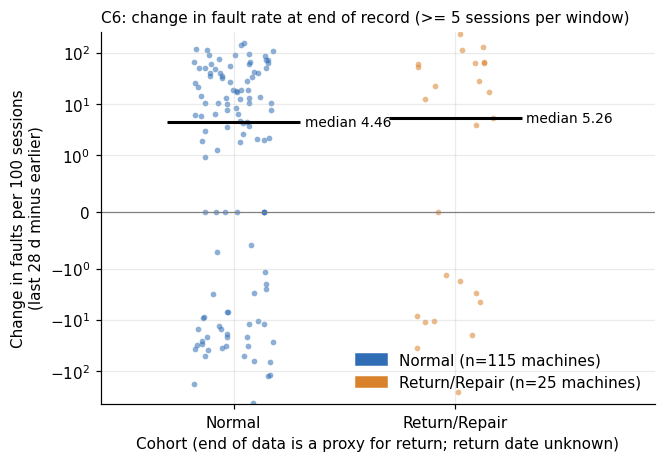

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4.4))
h.strip_compare(ax, c6, 'change', 'Change in faults per 100 sessions\n(last 28 d minus earlier)',
                'C6: change in fault rate at end of record (>= 5 sessions per window)', log=True, nonneg=False)
ax.axhline(0, color='grey', lw=0.8); ax.set_xlabel('Cohort (end of data is a proxy for return; return date unknown)')
f6p = h.save(fig, 'c6_end_of_record.png'); plt.show()
SHORTLIST.append(dict(id='C6', name='Warning signs: last 28 days vs earlier', metric='Change in faults per 100 sessions, last 28 d minus earlier (median per machine)', table=r6, chart=f6p.name,
  trust='Same as C1. The window is anchored on the last session date, a proxy for return (return date not known).',
  risks='Small samples (needs >= 5 sessions in both windows); end-of-record effects in both cohorts; machines still active at collection end are not "ended"; fault and session clocks differ; selected population.',
  sowhat='Hypothesis (reliability): Normal machines also show a higher rate in their last 28 days, so any end-of-record rise is not specific to RR; the RR - Normal gap in the change is not distinguishable from zero. Return date needed before this can be tested.',
  extra=pd.DataFrame(w).round(2), extra_title='Within-cohort change (median of last 28 d minus earlier, bootstrap interval of the median):'))

# 6b: Follow-up checks on the final candidates

Same method as above (machine-level medians, bootstrap 95% interval of the difference, 2,000 resamples, fixed seed, n per group). Numbers only; no causes. Decisions applied from the review:
- **Airway blockage (fault_type 12) is the main fault measure.** Filter Wash (13/1, "needs cleaning") is treated here as a **maintenance alert; this grouping is ours, not the brief's.** Fault rates are shown with and without it.
- 12/1 and 13/1 share results are **checked, not robust** (the direction flips under SV53-only); they are not findings.
- Region and sub-model checks are run for the final candidates only (airway blockage, motor runtime per day).
- "Direction holds" is always relative to the reference named in each table (same sign of the difference).

In [22]:
S6B = []   # blocks for the 6b section of shortlist.md: dict(title, note, table)
S6SUM = []  # one row per check for the summary table

b6 = c2.merge(elig[['anonymized_serial', 'region']], on='anonymized_serial', how='left')
b6['n_t12'] = b6.n_t12_v1 + b6.n_t12_v2
b6['n_all'] = b6.n_t11_v2 + b6.n_t12_v1 + b6.n_t12_v2 + b6.n_t13_v1
b6['n_not13'] = b6.n_all - b6.n_t13_v1
assert (b6.merge(elig[['anonymized_serial', 'n_faults_primary']], on='anonymized_serial').pipe(lambda d: (d.n_all == d.n_faults_primary).all()))
for k in ['t12', 'all', 'not13']:
    b6['rate_' + k] = 100.0 * b6['n_' + k] / b6.n_sessions
b6['fam'] = b6.model.fillna('').str[:4]
B6_COLS = {  # label -> (count column, per-machine rate column)
    'all fault types': ('n_all', 'rate_all'),
    'excluding 13/1 (Filter Wash maintenance alert, our grouping)': ('n_not13', 'rate_not13'),
    'type 12 airway blockage (values 1+2)': ('n_t12', 'rate_t12'),
    '12/1 inlet blocked, motor running': ('n_t12_v1', 'rate_t12_v1'),
    '12/2 inlet blocked and in error': ('n_t12_v2', 'rate_t12_v2'),
    '13/1 Filter Wash needs cleaning (maintenance alert, our grouping)': ('n_t13_v1', 'rate_t13_v1'),
    '11/2 Battery Temperature HOT': ('n_t11_v2', 'rate_t11_v2'),
}

def grid(groups, variants, ref, **grp):
    out = []
    for g in groups:
        num, rate = B6_COLS[g]
        rows = []
        for vname, d in variants.items():
            for r in h.three_stats(d, num, 'n_sessions', rate, **grp):
                r['group'] = g; r['variant'] = vname; rows.append(r)
        out.append(h.with_direction(pd.DataFrame(rows), ref))
    t_ = pd.concat(out, ignore_index=True)
    return t_[['group', 'measure', 'variant', 'n_normal', 'n_rr', 'normal', 'rr', 'diff', 'ratio', 'ci_lo', 'ci_hi', 'direction_holds']]

def summ(check, t_, group, measure, ref_label):
    for _, r in t_[(t_.group == group) & (t_.measure == measure)].iterrows():
        S6SUM.append(dict(check=check, measure=group + ' / ' + measure, variant=r.variant, n='%d / %d' % (r.n_normal, r.n_rr),
                          normal=r.normal, rr=r.rr, diff=r['diff'], ci='[%.3g, %.3g]' % (r.ci_lo, r.ci_hi), direction_holds=r.direction_holds, reference=ref_label))

## 6b-0. Fault rates with and without Filter Wash (13/1)
Normal vs RR, all eligible machines and SV53 only. "pooled rate" = sum of faults / sum of sessions x 100. Reference for direction = all eligible machines.

In [23]:
v0 = {'all eligible machines': b6, 'SV53 only': h.sv53(b6)}
t0 = grid(['all fault types', 'excluding 13/1 (Filter Wash maintenance alert, our grouping)', 'type 12 airway blockage (values 1+2)',
           '13/1 Filter Wash needs cleaning (maintenance alert, our grouping)'], v0, 'all eligible machines')
display(t0.round(3))
S6B.append(dict(title='6b-0 Fault rates with and without Filter Wash (13/1)', note='Per 100 clean sessions. Direction reference: all eligible machines (RR minus Normal). 13/1 grouped as a maintenance alert is our grouping, not the brief\'s.', table=t0))
for g in t0.group.unique():
    summ('6b-0', t0, g, 'pooled rate', 'all eligible machines')

,group,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,all fault types,median per machine,all eligible machines,158,36,6.534,9.688,3.154,1.483,-3.445,14.452,(reference)
1,all fault types,pooled rate,all eligible machines,158,36,11.890,18.678,6.788,1.571,-5.101,27.154,(reference)
2,all fault types,share of machines with >=1,all eligible machines,158,36,0.867,0.889,0.022,1.025,-0.102,0.133,(reference)
3,all fault types,median per machine,SV53 only,59,36,1.111,9.688,8.577,8.720,2.922,18.893,yes
4,all fault types,pooled rate,SV53 only,59,36,4.286,18.678,14.392,4.358,2.432,34.351,yes
5,all fault types,share of machines with >=1,SV53 only,59,36,0.814,0.889,0.075,1.093,-0.076,0.222,yes
6,"excluding 13/1 (Filter Wash maintenance alert,...",median per machine,all eligible machines,158,36,1.865,7.027,5.162,3.767,0.040,13.247,(reference)
7,"excluding 13/1 (Filter Wash maintenance alert,...",pooled rate,all eligible machines,158,36,4.229,13.090,8.861,3.095,0.560,23.346,(reference)
8,"excluding 13/1 (Filter Wash maintenance alert,...",share of machines with >=1,all eligible machines,158,36,0.728,0.861,0.133,1.183,-0.001,0.262,(reference)
9,"excluding 13/1 (Filter Wash maintenance alert,...",median per machine,SV53 only,59,36,0.935,7.027,6.093,7.519,0.864,14.258,yes


## 6b-a. SV50 vs SV53 within Normal: type/value rates and the share of the gap that is Filter Wash
Group A = Normal SV50, group B = Normal SV53 (columns `normal` / `rr` below mean SV50 / SV53). Direction reference for each row: the sign of the same measure for **all fault types**.

In [24]:
nrm = b6[b6.cohort == h.NORMAL]
ga = dict(group='fam', a_val='SV50', b_val='SV53')
rows = []
for g in B6_COLS:
    num, rate = B6_COLS[g]
    for r in h.three_stats(nrm, num, 'n_sessions', rate, **ga):
        r['group'] = g; rows.append(r)
ta = pd.DataFrame(rows)
ref = ta[ta.group == 'all fault types'].set_index('measure')['diff']
ta['direction_holds'] = [('(reference)' if r.group == 'all fault types' else h.direction_holds(ref[r.measure], r['diff'])) for _, r in ta.iterrows()]
ta = ta.rename(columns={'normal': 'SV50', 'rr': 'SV53', 'n_normal': 'n SV50', 'n_rr': 'n SV53', 'diff': 'SV53 - SV50', 'ratio': 'SV53 / SV50'})
ta = ta[['group', 'measure', 'n SV50', 'n SV53', 'SV50', 'SV53', 'SV53 - SV50', 'SV53 / SV50', 'ci_lo', 'ci_hi', 'direction_holds']]
display(ta.round(3))
pool = ta[ta.measure == 'pooled rate'].set_index('group')
tot_gap = pool.loc['all fault types', 'SV53 - SV50']
dec = pd.DataFrame({'SV50 pooled': pool['SV50'], 'SV53 pooled': pool['SV53'], 'gap (SV53 - SV50)': pool['SV53 - SV50']})
dec['share of total gap'] = dec['gap (SV53 - SV50)'] / tot_gap
dec = dec.loc[['all fault types', '12/1 inlet blocked, motor running', '12/2 inlet blocked and in error', '13/1 Filter Wash needs cleaning (maintenance alert, our grouping)', '11/2 Battery Temperature HOT', 'excluding 13/1 (Filter Wash maintenance alert, our grouping)']]
display(dec.round(3))
print('Pooled rates add up across types: 12/1 + 12/2 + 13/1 + 11/2 gap =', round(dec.iloc[1:5, 2].sum(), 3), 'vs all types', round(tot_gap, 3))
S6B.append(dict(title='6b-a Within Normal: SV50 vs SV53 by fault type/value', note='Group A = SV50, group B = SV53 (both Normal, rate-eligible). Direction reference: all fault types, same measure.', table=ta))
S6B.append(dict(title='6b-a (decomposition) Share of the SV50 vs SV53 pooled-rate gap by type/value', note='Pooled rates (faults per 100 sessions) add up across types, so the shares sum to 100%.', table=dec.reset_index().rename(columns={'index': 'group'})))
for g in ['all fault types', '12/2 inlet blocked and in error', '13/1 Filter Wash needs cleaning (maintenance alert, our grouping)']:
    r = ta[(ta.group == g) & (ta.measure == 'pooled rate')].iloc[0]
    S6SUM.append(dict(check='6b-a', measure=g + ' / pooled rate, SV53 - SV50 within Normal', variant='Normal only', n='%d / %d' % (r['n SV50'], r['n SV53']),
                      normal=r['SV50'], rr=r['SV53'], diff=r['SV53 - SV50'], ci='[%.3g, %.3g]' % (r.ci_lo, r.ci_hi), direction_holds=r.direction_holds, reference='all fault types'))

,group,measure,n SV50,n SV53,SV50,SV53,SV53 - SV50,SV53 / SV50,ci_lo,ci_hi,direction_holds
0,all fault types,median per machine,99,59,16.770,1.111,-15.659,0.066,-20.556,-10.731,(reference)
1,all fault types,pooled rate,99,59,16.535,4.286,-12.249,0.259,-17.877,-7.258,(reference)
2,all fault types,share of machines with >=1,99,59,0.899,0.814,-0.085,0.905,-0.207,0.026,(reference)
3,"excluding 13/1 (Filter Wash maintenance alert,...",median per machine,99,59,2.662,0.935,-1.727,0.351,-3.322,-0.483,yes
4,"excluding 13/1 (Filter Wash maintenance alert,...",pooled rate,99,59,5.095,2.812,-2.283,0.552,-5.334,0.714,yes
5,"excluding 13/1 (Filter Wash maintenance alert,...",share of machines with >=1,99,59,0.768,0.661,-0.107,0.861,-0.259,0.035,yes
6,type 12 airway blockage (values 1+2),median per machine,99,59,2.662,0.935,-1.727,0.351,-3.322,-0.467,yes
7,type 12 airway blockage (values 1+2),pooled rate,99,59,5.089,2.812,-2.278,0.552,-5.334,0.725,yes
8,type 12 airway blockage (values 1+2),share of machines with >=1,99,59,0.768,0.661,-0.107,0.861,-0.259,0.035,yes
9,"12/1 inlet blocked, motor running",median per machine,99,59,2.083,0.000,-2.083,0.000,-2.857,-1.521,yes


,SV50 pooled,SV53 pooled,gap (SV53 - SV50),share of total gap
group,,,,
all fault types,16.535,4.286,-12.249,1.000
"12/1 inlet blocked, motor running",3.592,1.706,-1.886,0.154
12/2 inlet blocked and in error,1.497,1.106,-0.392,0.032
"13/1 Filter Wash needs cleaning (maintenance alert, our grouping)",11.440,1.474,-9.966,0.814
11/2 Battery Temperature HOT,0.005,0.000,-0.005,0.000
"excluding 13/1 (Filter Wash maintenance alert, our grouping)",5.095,2.812,-2.283,0.186


Pooled rates add up across types: 12/1 + 12/2 + 13/1 + 11/2 gap = -12.249 vs all types -12.249


## 6b-b. Airway blockage (type 12): Normal vs RR
Values 1 and 2 together, and 12/2 alone; all models and SV53 only. Reference for direction = all models (and the SV53-only row is the matched comparison).

In [25]:
vb = {'all models': b6, 'SV53 only': h.sv53(b6)}
tb = grid(['type 12 airway blockage (values 1+2)', '12/2 inlet blocked and in error'], vb, 'all models')
display(tb.round(3))
S6B.append(dict(title='6b-b Airway blockage (type 12): Normal vs RR', note='Per 100 clean sessions; rate-eligible machines. Direction reference: all models.', table=tb))
for g in tb.group.unique():
    for m_ in ['pooled rate', 'median per machine', 'share of machines with >=1']:
        summ('6b-b', tb, g, m_, 'all models')

,group,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,type 12 airway blockage (values 1+2),median per machine,all models,158,36,1.837,7.027,5.190,3.825,0.044,13.261,(reference)
1,type 12 airway blockage (values 1+2),pooled rate,all models,158,36,4.226,13.090,8.864,3.098,0.560,23.353,(reference)
2,type 12 airway blockage (values 1+2),share of machines with >=1,all models,158,36,0.728,0.861,0.133,1.183,-0.001,0.262,(reference)
3,type 12 airway blockage (values 1+2),median per machine,SV53 only,59,36,0.935,7.027,6.093,7.519,0.864,14.258,yes
4,type 12 airway blockage (values 1+2),pooled rate,SV53 only,59,36,2.812,13.090,10.278,4.656,1.658,24.744,yes
5,type 12 airway blockage (values 1+2),share of machines with >=1,SV53 only,59,36,0.661,0.861,0.200,1.303,0.033,0.362,yes
6,12/2 inlet blocked and in error,median per machine,all models,158,36,0.067,1.527,1.460,22.810,-0.258,4.154,(reference)
7,12/2 inlet blocked and in error,pooled rate,all models,158,36,1.349,6.501,5.152,4.820,1.249,11.654,(reference)
8,12/2 inlet blocked and in error,share of machines with >=1,all models,158,36,0.500,0.611,0.111,1.222,-0.078,0.275,(reference)
9,12/2 inlet blocked and in error,median per machine,SV53 only,59,36,0.000,1.527,1.527,NaN,-0.258,4.310,yes


## 6b-c. Region and sub-model checks (airway blockage SV53; C4c motor runtime per day)
Restrict to region ROW-PROD (CN-PROD appears almost only in Normal), show the SV53 sub-model mix per cohort, and compare SV53-AB only where both cohorts have >= 10 machines. Direction reference: the SV53-only airway result (b) and the main C4c result.

In [26]:
s53 = h.sv53(b6)
mix_b = pd.crosstab(s53.model, s53.cohort.map(h.LABELS)); mix_b.loc['Total'] = mix_b.sum()
c4c_m = c4c.copy(); mm53 = c4c_m
mix_c = pd.crosstab(c4c_m.model.fillna('(model not available)'), c4c_m.cohort.map(h.LABELS)); mix_c.loc['Total'] = mix_c.sum()
print('SV53 sub-model mix, airway-blockage sample (rate-eligible SV53 machines)'); display(mix_b)
print('Sub-model mix, C4c motor sample'); display(mix_c)
print('Region of the same samples'); display(pd.crosstab(s53.region.fillna('NA'), s53.cohort.map(h.LABELS))); display(pd.crosstab(c4c_m.region.fillna('NA'), c4c_m.cohort.map(h.LABELS)))

def enough(d, k=10):
    n = d.groupby('cohort').size().reindex([h.NORMAL, h.RR]).fillna(0)
    return bool((n >= k).all()), n.to_dict()

vc = {'SV53 only': s53, 'SV53, ROW-PROD only': s53[s53.region == 'ROW-PROD']}
ab = s53[s53.model == 'SV53-AB']; ok, n_ab = enough(ab)
print('SV53-AB only, machines per cohort:', n_ab, '-> run' if ok else '-> not run (< 10 in a cohort)')
if ok:
    vc['SV53-AB only'] = ab
    vc['SV53-AB, ROW-PROD only'] = ab[ab.region == 'ROW-PROD']
tc = grid(['type 12 airway blockage (values 1+2)', '12/2 inlet blocked and in error'], vc, 'SV53 only')
display(tc.round(3))
S6B.append(dict(title='6b-c Airway blockage SV53: region and sub-model checks', note='Direction reference: SV53 only. Sub-model mix and region mix are in the notebook output; SV53-AB run only if >= 10 machines in both cohorts (n: %s).' % n_ab, table=tc))
for g in tc.group.unique():
    summ('6b-c', tc, g, 'pooled rate', 'SV53 only')

# C4c (motor minutes per day, median per machine)
vm = {'all motor machines (main C4c)': c4c, 'ROW-PROD only': c4c[c4c.region == 'ROW-PROD']}
ok2, n_ab2 = enough(c4c[c4c.model == 'SV53-AB'])
print('C4c SV53-AB machines per cohort:', n_ab2, '-> run' if ok2 else '-> not run')
if ok2:
    vm['SV53-AB only'] = c4c[c4c.model == 'SV53-AB']
    vm['SV53-AB, ROW-PROD only'] = c4c[(c4c.model == 'SV53-AB') & (c4c.region == 'ROW-PROD')]
tm = []
for vname, d in vm.items():
    r = h.compare(d, 'motor_min_per_day'); r['variant'] = vname; tm.append(r)
tm = pd.DataFrame(tm)
ref_m = tm.iloc[0]['diff']
tm['direction_holds'] = ['(reference)'] + [h.direction_holds(ref_m, x) for x in tm['diff'][1:]]
tm = tm[['variant', 'n_normal', 'n_rr', 'normal', 'rr', 'diff', 'ratio', 'ci_lo', 'ci_hi', 'direction_holds']]
display(tm.round(3))
S6B.append(dict(title='6b-c C4c motor runtime per day: region and sub-model checks', note='Minutes per day, median per machine. Direction reference: all motor machines (main C4c).', table=tm))
for _, r in tm.iterrows():
    S6SUM.append(dict(check='6b-c', measure='motor runtime min/day / median per machine', variant=r.variant, n='%d / %d' % (r.n_normal, r.n_rr), normal=r.normal, rr=r.rr, diff=r['diff'], ci='[%.3g, %.3g]' % (r.ci_lo, r.ci_hi), direction_holds=r.direction_holds, reference='all motor machines (main C4c)'))
S6B.append(dict(title='6b-c Sub-model mix (airway-blockage SV53 sample)', note='Machines per SV53 sub-model and cohort.', table=mix_b.reset_index().rename(columns={'model': 'sub-model'})))
S6B.append(dict(title='6b-c Sub-model mix (C4c motor sample)', note='Machines per model and cohort.', table=mix_c.reset_index().rename(columns={'model': 'sub-model'})))

SV53 sub-model mix, airway-blockage sample (rate-eligible SV53 machines)


cohort,Normal,Return/Repair
model,,
SV53-AA,2,0
SV53-AB,18,21
SV53-AC,4,2
SV53-AE,5,2
SV53-AF,30,11
Total,59,36


Sub-model mix, C4c motor sample


cohort,Normal,Return/Repair
model,,
SV53-AA,2,0
SV53-AB,15,22
SV53-AC,4,2
SV53-AE,5,3
SV53-AF,28,9
Total,54,36


Region of the same samples


...

cohort,Normal,Return/Repair
region,,
CN-PROD,5,1
ROW-PROD,49,35


SV53-AB only, machines per cohort: {'normal': 18, 'return_repair': 21} -> run


,group,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,type 12 airway blockage (values 1+2),median per machine,SV53 only,59,36,0.935,7.027,6.093,7.519,0.864,14.258,(reference)
1,type 12 airway blockage (values 1+2),pooled rate,SV53 only,59,36,2.812,13.090,10.278,4.656,1.658,24.744,(reference)
2,type 12 airway blockage (values 1+2),share of machines with >=1,SV53 only,59,36,0.661,0.861,0.200,1.303,0.033,0.362,(reference)
3,type 12 airway blockage (values 1+2),median per machine,"SV53, ROW-PROD only",54,35,1.079,6.809,5.729,6.309,0.557,14.037,yes
4,type 12 airway blockage (values 1+2),pooled rate,"SV53, ROW-PROD only",54,35,2.380,13.073,10.693,5.493,1.960,24.450,yes
5,type 12 airway blockage (values 1+2),share of machines with >=1,"SV53, ROW-PROD only",54,35,0.704,0.857,0.153,1.218,-0.016,0.320,yes
6,type 12 airway blockage (values 1+2),median per machine,SV53-AB only,18,21,2.229,7.246,5.017,3.250,-2.737,18.478,yes
7,type 12 airway blockage (values 1+2),pooled rate,SV53-AB only,18,21,8.159,17.038,8.880,2.088,-8.588,33.822,yes
8,type 12 airway blockage (values 1+2),share of machines with >=1,SV53-AB only,18,21,0.722,0.952,0.230,1.319,0.016,0.452,yes
9,type 12 airway blockage (values 1+2),median per machine,"SV53-AB, ROW-PROD only",17,21,1.429,7.246,5.818,5.072,-1.779,18.478,yes


C4c SV53-AB machines per cohort: {'normal': 15, 'return_repair': 22} -> run


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,all motor machines (main C4c),54,36,2.384,4.869,2.485,2.042,0.430,3.979,(reference)
1,ROW-PROD only,49,35,2.460,5.049,2.589,2.052,0.291,4.074,yes
2,SV53-AB only,15,22,1.714,4.212,2.498,2.458,-0.447,5.377,yes
3,"SV53-AB, ROW-PROD only",14,22,1.619,4.212,2.593,2.602,-0.599,5.541,yes


## 6b-d. Motor runtime per day over calendar months where both cohorts have motor periods
Only **valid** motor periods are used. Each period is allocated to the calendar months it overlaps by day. A month is "common" if >= 10 machines of each cohort have a period overlapping it (my threshold). Two versions: (1) whole periods that lie inside the common window; (2) periods pro-rated to the common months by day overlap (**assumes runtime is spread evenly across a period**). Direction reference: main C4c.

In [27]:
mv = t['motor'][t['motor'].delta_valid & (t['motor'].days_elapsed > 0)].copy()
recs = []
for _, r in mv.iterrows():
    cur = r.period_start_ts.normalize().replace(day=1)
    while cur < r.period_end_ts:
        nxt = (cur + pd.offsets.MonthBegin(1))
        ov = (min(nxt, r.period_end_ts) - max(cur, r.period_start_ts)).total_seconds() / 86400.0
        if ov > 0:
            recs.append((r.anonymized_serial, r.cohort, cur.strftime('%Y-%m'), ov, r.delta_runtime_s * ov / r.days_elapsed))
        cur = nxt
lm = pd.DataFrame(recs, columns=['anonymized_serial', 'cohort', 'month', 'days', 'runtime_s'])
mc = lm.groupby(['month', 'cohort']).anonymized_serial.nunique().unstack(fill_value=0).reindex(columns=[h.NORMAL, h.RR]).fillna(0).astype(int)
mc['common'] = (mc[h.NORMAL] >= 10) & (mc[h.RR] >= 10)
display(mc.rename(columns=h.LABELS))
common = list(mc.index[mc.common])
print('common months:', common)
ws = pd.Timestamp(common[0] + '-01'); we = pd.Timestamp(common[-1] + '-01') + pd.offsets.MonthBegin(1)
assert common == list(pd.period_range(common[0], common[-1], freq='M').astype(str)), 'common months are not contiguous'

# (1) whole periods inside the window
w1 = mv[(mv.period_start_ts >= ws) & (mv.period_end_ts <= we)]
g1 = w1.groupby(['anonymized_serial', 'cohort']).agg(rt=('delta_runtime_s', 'sum'), dd=('days_elapsed', 'sum')).reset_index()
g1['motor_min_per_day'] = g1.rt / g1.dd / 60.0
# (2) pro-rated to common months
l2 = lm[lm.month.isin(common)]
g2 = l2.groupby(['anonymized_serial', 'cohort']).agg(rt=('runtime_s', 'sum'), dd=('days', 'sum')).reset_index()
g2['motor_min_per_day'] = g2.rt / g2.dd / 60.0
td = []
for vname, d in [('main C4c (all valid periods)', c4c), ('whole periods inside common window', g1), ('pro-rated to common months', g2)]:
    r = h.compare(d, 'motor_min_per_day'); r['variant'] = vname; td.append(r)
td = pd.DataFrame(td); ref_d = td.iloc[0]['diff']
td['direction_holds'] = ['(reference)'] + [h.direction_holds(ref_d, x) for x in td['diff'][1:]]
td = td[['variant', 'n_normal', 'n_rr', 'normal', 'rr', 'diff', 'ratio', 'ci_lo', 'ci_hi', 'direction_holds']]
display(td.round(3))
S6B.append(dict(title='6b-d Motor runtime per day over common calendar months', note='Common months (>= 10 machines per cohort with a valid period overlapping the month): %s to %s. Minutes per day, median per machine. Pro-rating assumes even use within a period.' % (common[0], common[-1]), table=td))
S6B.append(dict(title='6b-d Machines with a valid motor period per calendar month', note='Distinct machines by month (by day overlap); common = >= 10 in both cohorts.', table=mc.reset_index().rename(columns=dict(h.LABELS, month='month'))))
for _, r in td.iterrows():
    S6SUM.append(dict(check='6b-d', measure='motor runtime min/day / median per machine', variant=r.variant, n='%d / %d' % (r.n_normal, r.n_rr), normal=r.normal, rr=r.rr, diff=r['diff'], ci='[%.3g, %.3g]' % (r.ci_lo, r.ci_hi), direction_holds=r.direction_holds, reference='main C4c'))

cohort,Normal,Return/Repair,common
month,,,
2025-08,2,1,False
2025-09,51,3,False
2025-10,52,15,True
2025-11,52,23,True
2025-12,50,25,True
2026-01,49,26,True
2026-02,47,25,True
2026-03,44,16,True
2026-04,39,15,True


common months: ['2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05']


,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,main C4c (all valid periods),54,36,2.384,4.869,2.485,2.042,0.430,3.979,(reference)
1,whole periods inside common window,52,36,2.167,4.446,2.279,2.052,0.488,3.905,yes
2,pro-rated to common months,54,36,2.288,4.869,2.581,2.128,0.544,3.957,yes


## 6b-e. Exposure check: airway blockage (type 12) per hour of motor runtime
SV53 machines with both fault data (in the faults table) and at least one valid motor period. For each machine, the window runs from its first valid-period start to its last valid-period end; faults are the type 12 occurrences (primary rule) with `fault_timestamp` in that window (zero if none); runtime is the sum of valid-period runtime in hours. Machines with < 1 hour of runtime are excluded in the main version (no-minimum version as a check). Direction reference: the SV53-only airway result in 6b-b (RR higher).

In [28]:
vp = mv.copy()
win = vp.groupby('anonymized_serial').agg(ws=('period_start_ts', 'min'), we=('period_end_ts', 'max'), rt_s=('delta_runtime_s', 'sum'))
f12 = ff[ff.fault_type == 12][['anonymized_serial', 'fault_timestamp', 'fault_value']].merge(win, left_on='anonymized_serial', right_index=True)
f12 = f12[(f12.fault_timestamp >= f12.ws) & (f12.fault_timestamp <= f12.we)]
n12 = f12.groupby('anonymized_serial').size().rename('n_t12_win')
n122 = f12[f12.fault_value == 2].groupby('anonymized_serial').size().rename('n_t12_2_win')
e = (ms[['anonymized_serial', 'cohort', 'model', 'has_fault_analysis_rows']].join(win, on='anonymized_serial', how='inner')
     .join(n12, on='anonymized_serial').join(n122, on='anonymized_serial'))
e[['n_t12_win', 'n_t12_2_win']] = e[['n_t12_win', 'n_t12_2_win']].fillna(0)
e['hours'] = e.rt_s / 3600.0
e = h.sv53(e[e.has_fault_analysis_rows])
e['rate_t12_per_h'] = e.n_t12_win / e.hours
e['rate_t12_2_per_h'] = e.n_t12_2_win / e.hours
print('SV53 machines with fault data and valid motor periods:', e.groupby('cohort').size().to_dict(), '| with >= 1 h runtime:', e[e.hours >= 1].groupby('cohort').size().to_dict())
ref_b = tb[(tb.group == 'type 12 airway blockage (values 1+2)') & (tb.measure == 'pooled rate') & (tb.variant == 'SV53 only')]['diff'].iloc[0]
rows = []
for vname, d in [('>= 1 h runtime (main)', e[e.hours >= 1]), ('no minimum runtime', e)]:
    for gname, num, rate in [('type 12 (values 1+2)', 'n_t12_win', 'rate_t12_per_h'), ('12/2 alone', 'n_t12_2_win', 'rate_t12_2_per_h')]:
        for r in h.three_stats(d, num, 'hours', rate, scale=1.0):
            r['group'] = gname; r['variant'] = vname
            r['measure'] = r['measure'].replace('pooled rate', 'pooled faults per runtime hour').replace('median per machine', 'median faults per runtime hour')
            rows.append(r)
te = pd.DataFrame(rows)
te['direction_holds'] = [h.direction_holds(ref_b, x) for x in te['diff']]
te = te[['group', 'measure', 'variant', 'n_normal', 'n_rr', 'normal', 'rr', 'diff', 'ratio', 'ci_lo', 'ci_hi', 'direction_holds']]
display(te.round(4))
print('Total type 12 faults in windows and runtime hours by cohort:'); display(e[e.hours >= 1].groupby('cohort').agg(machines=('hours', 'size'), faults=('n_t12_win', 'sum'), runtime_hours=('hours', 'sum')).round(1))
S6B.append(dict(title='6b-e Exposure: airway blockage per hour of motor runtime', note='SV53 machines in the faults table with a valid motor period; faults counted in each machine\'s motor observation window. Direction reference: SV53-only airway result (6b-b), RR higher.', table=te))
for _, r in te[te.measure != 'share of machines with >=1'].iterrows():
    S6SUM.append(dict(check='6b-e', measure=r.group + ' / ' + r.measure, variant=r.variant, n='%d / %d' % (r.n_normal, r.n_rr), normal=r.normal, rr=r.rr, diff=r['diff'], ci='[%.3g, %.3g]' % (r.ci_lo, r.ci_hi), direction_holds=r.direction_holds, reference='6b-b SV53 pooled rate'))

SV53 machines with fault data and valid motor periods: {'normal': 47, 'return_repair': 32} | with >= 1 h runtime: {'normal': 45, 'return_repair': 30}


,group,measure,variant,n_normal,n_rr,normal,rr,diff,ratio,ci_lo,ci_hi,direction_holds
0,type 12 (values 1+2),median faults per runtime hour,>= 1 h runtime (main),45,30,0.0000,0.6267,0.6267,NaN,0.2048,1.7399,yes
1,type 12 (values 1+2),pooled faults per runtime hour,>= 1 h runtime (main),45,30,0.3205,1.7321,1.4116,5.4039,0.1727,3.1211,yes
2,type 12 (values 1+2),share of machines with >=1,>= 1 h runtime (main),45,30,0.4222,0.7333,0.3111,1.7368,0.1000,0.5222,yes
3,12/2 alone,median faults per runtime hour,>= 1 h runtime (main),45,30,0.0000,0.2172,0.2172,NaN,0.0000,0.6911,yes
4,12/2 alone,pooled faults per runtime hour,>= 1 h runtime (main),45,30,0.0904,0.8727,0.7822,9.6487,0.2315,1.5141,yes
5,12/2 alone,share of machines with >=1,>= 1 h runtime (main),45,30,0.4000,0.6000,0.2000,1.5000,-0.0114,0.4225,yes
6,type 12 (values 1+2),median faults per runtime hour,no minimum runtime,47,32,0.0000,0.8936,0.8936,NaN,0.2407,1.8534,yes
7,type 12 (values 1+2),pooled faults per runtime hour,no minimum runtime,47,32,0.3198,1.7482,1.4284,5.4660,0.1428,3.1256,yes
8,type 12 (values 1+2),share of machines with >=1,no minimum runtime,47,32,0.4043,0.7500,0.3457,1.8553,0.1370,0.5559,yes
9,12/2 alone,median faults per runtime hour,no minimum runtime,47,32,0.0000,0.2172,0.2172,NaN,0.0000,0.6911,yes


Total type 12 faults in windows and runtime hours by cohort:


,machines,faults,runtime_hours
cohort,,,
normal,45,202.0,630.2
return_repair,30,522.0,301.4


## Checked, not robust (one line each)
- **12/1 airway blocked, motor still running, share of machines with >= 1:** Normal 61.4% vs RR 50.0% (all eligible); sign flips under SV53-only (35.6% vs 50.0%). Not a finding.
- **13/1 Filter Wash, share of machines with >= 1 and pooled rate:** Normal 69.6% vs RR 50.0%, pooled 7.66 vs 5.59; both flip under SV53-only (42.4% vs 50.0%; 1.47 vs 5.59). Treated as a maintenance alert (our grouping); not a finding.

In [29]:
summ6 = pd.DataFrame(S6SUM)
display(summ6.round(3))

,check,measure,variant,n,normal,rr,diff,ci,direction_holds,reference
0,6b-0,all fault types / pooled rate,all eligible machines,158 / 36,11.890,18.678,6.788,"[-5.1, 27.2]",(reference),all eligible machines
1,6b-0,all fault types / pooled rate,SV53 only,59 / 36,4.286,18.678,14.392,"[2.43, 34.4]",yes,all eligible machines
2,6b-0,"excluding 13/1 (Filter Wash maintenance alert,...",all eligible machines,158 / 36,4.229,13.090,8.861,"[0.56, 23.3]",(reference),all eligible machines
3,6b-0,"excluding 13/1 (Filter Wash maintenance alert,...",SV53 only,59 / 36,2.812,13.090,10.278,"[1.66, 24.7]",yes,all eligible machines
4,6b-0,type 12 airway blockage (values 1+2) / pooled ...,all eligible machines,158 / 36,4.226,13.090,8.864,"[0.56, 23.4]",(reference),all eligible machines
5,6b-0,type 12 airway blockage (values 1+2) / pooled ...,SV53 only,59 / 36,2.812,13.090,10.278,"[1.66, 24.7]",yes,all eligible machines
6,6b-0,13/1 Filter Wash needs cleaning (maintenance a...,all eligible machines,158 / 36,7.661,5.588,-2.073,"[-6.26, 3.98]",(reference),all eligible machines
7,6b-0,13/1 Filter Wash needs cleaning (maintenance a...,SV53 only,59 / 36,1.474,5.588,4.114,"[0.176, 9.74]",no,all eligible machines
8,6b-a,"all fault types / pooled rate, SV53 - SV50 wit...",Normal only,99 / 59,16.535,4.286,-12.249,"[-17.9, -7.26]",(reference),all fault types
9,6b-a,"12/2 inlet blocked and in error / pooled rate,...",Normal only,99 / 59,1.497,1.106,-0.392,"[-1.51, 0.46]",yes,all fault types


## Shortlist table and output
Collects every candidate into `reports/eda/shortlist.md`.

In [30]:
def fnum(x):
    return '' if pd.isna(x) else ('%.3g' % x)

def robust_text(tab):
    parts = []
    for _, r in tab.iterrows():
        if r.direction_holds == '(reference)':
            continue
        parts.append('%s: %s (%s vs %s, diff %s; n %d/%d)' % (r.variant, r.direction_holds, fnum(r.normal), fnum(r.rr), fnum(r['diff']), r.n_normal, r.n_rr))
    return '; '.join(parts)

summary_rows, detail = [], []
for it in SHORTLIST:
    tab = it['table']
    if 'measure' in tab.columns:
        blocks = [(m_, tab[tab.measure == m_].drop(columns='measure').reset_index(drop=True)) for m_ in tab.measure.unique()]
    else:
        blocks = [(None, tab)]
    for m_, b in blocks:
        r0 = b.iloc[0]
        summary_rows.append({
            'id': it['id'], 'metric': it['metric'] if m_ is None else it['name'] + ' - ' + m_ + (' (fraction of machines)' if 'share' in m_ else ''),
            'n Normal / RR': '%d / %d' % (r0.n_normal, r0.n_rr),
            'Normal': fnum(r0.normal),
            'RR': fnum(r0.rr), 'RR - Normal': fnum(r0['diff']), 'RR / Normal': fnum(r0.ratio),
            'bootstrap 95% (diff)': '[%s, %s]' % (fnum(r0.ci_lo), fnum(r0.ci_hi)),
            'direction holds (robustness)': robust_text(b),
            'field trust': it['trust'], 'chart': 'reports/figures/eda/' + it['chart'],
            'risks': it['risks'], 'draft so what (hypothesis)': it['sowhat']})
        detail.append((it, m_, b))
summ = pd.DataFrame(summary_rows)
display(summ[['id', 'metric', 'n Normal / RR', 'RR', 'RR - Normal', 'RR / Normal', 'bootstrap 95% (diff)']])

,id,metric,n Normal / RR,RR,RR - Normal,RR / Normal,bootstrap 95% (diff)
0,C1,"Faults per 100 clean sessions, per machine (me...",158 / 36,9.69,3.15,1.48,"[-3.45, 14.5]"
1,C2,Fault mix: 11/2 Battery Temperature: HOT - % m...,158 / 36,0,-0.00633,0,"[-0.019, 0]"
2,C2,Fault mix: 11/2 Battery Temperature: HOT - poo...,158 / 36,0,-0.00325,0,"[-0.0107, 0]"
3,C2,Fault mix: 12/1 Airway Blockage: inlet blocked...,158 / 36,0.5,-0.114,0.814,"[-0.291, 0.0629]"
4,C2,Fault mix: 12/1 Airway Blockage: inlet blocked...,158 / 36,6.59,3.71,2.29,"[-1.43, 12.3]"
5,C2,Fault mix: 12/2 Airway Blockage: inlet blocked...,158 / 36,0.611,0.111,1.22,"[-0.0784, 0.275]"
6,C2,Fault mix: 12/2 Airway Blockage: inlet blocked...,158 / 36,6.5,5.15,4.82,"[1.25, 11.7]"
7,C2,Fault mix: 13/1 Filter Wash: needs cleaning [m...,158 / 36,0.5,-0.196,0.718,"[-0.376, -0.0193]"
8,C2,Fault mix: 13/1 Filter Wash: needs cleaning [m...,158 / 36,5.59,-2.07,0.729,"[-6.26, 3.98]"
9,C3,"Share of lifetime runtime at 300-400 W, per ma...",51 / 37,0.0641,0.00276,1.04,"[-0.0268, 0.134]"


In [31]:
RECO = '**Updated after 6b.** Take forward:\n\n1. **Airway blockage (type 12) per 100 sessions as the main fault measure** (12/2 alone as the stricter version). Pooled rate Normal 4.2 vs RR 13.1 (all models), SV53-only 2.8 vs 13.1 (interval 1.7 to 24.7), ROW-PROD only 2.4 vs 13.1; 12/2 alone SV53-only 1.1 vs 6.5 (interval 1.5 to 11.5). Direction holds in every region and sub-model variant; within SV53-AB only (18 vs 21 machines) the type 12 interval spans 0 but 12/2 alone excludes 0. It also holds per hour of motor runtime (SV53, 45 vs 30 machines: 0.32 vs 1.73 per runtime hour, interval 0.17 to 3.12).\n2. **Model effect on fault counts, shown separately.** Within Normal, SV53 vs SV50 total pooled rate is 4.3 vs 16.5, and Filter Wash (13/1, maintenance alert, our grouping) accounts for 81% of that gap; excluding it, the gap is -2.3 (interval -5.3 to 0.7). So the all-fault-types comparison between cohorts is mostly a model-mix and Filter Wash story and should be shown with and without 13/1, with type 12 as the headline.\n3. **C4c motor runtime per day.** RR about 2x Normal (4.9 vs 2.4 min/day); holds for ROW-PROD only (interval excludes 0), over common calendar months (both versions, intervals exclude 0) and SV53-AB only (direction holds, interval spans 0 with 15 vs 22 machines).\n4. **Optional: C5a battery used per session** (weak: whole-number medians, interval touches 0).\n\n**Drop / checked, not robust:** C3 (no difference), C5b (no spread), C6 (Normal also rises at end of record; RR - Normal not distinguishable), 12/1 and 13/1 share results (flip under SV53-only), 11/2 (one occurrence).\n'
FINAL = "Gate decision (user), recorded 2026-10-11. All results remain exploratory; Return/Repair (RR) is a selected population; no causes are claimed.\n\n**Method rule.** Fault rates are **pooled** (total faults / total sessions x 100), with bootstrap 95% intervals from resampling machines (2,000 resamples, fixed seed), because most machines have zero for rare fault types. Continuous measures (motor runtime per day, durations) use **machine-level medians** with the same bootstrap.\n\n**Final insights for Step 7**\n\n1. **Fault counts are driven by model, mainly Filter Wash (13/1); cohort comparisons must be like-for-like (SV53).** Within Normal, pooled faults per 100 sessions are 16.5 (SV50, 99 machines) vs 4.3 (SV53, 59 machines); Filter Wash is 11.4 vs 1.5 and makes up 81.4% of the gap. Excluding 13/1 the gap is -2.3 (interval -5.3 to 0.7). Filter Wash is treated as a maintenance alert; this grouping is ours, not the brief's. Step 7 chart: side-by-side fault rate with and without 13/1.\n2. **Among SV53 machines, RR raise airway blockage at several times the Normal rate, including per hour of motor runtime.** Type 12 (values 1+2), pooled per 100 sessions: Normal 2.8 vs RR 13.1 (4.7x; interval of the difference 1.7 to 24.7; 59 / 36 machines). 12/2 alone (stricter): 1.1 vs 6.5 (5.9x; 1.5 to 11.5). Per motor runtime hour (45 / 30 machines): type 12 0.32 vs 1.73 (5.4x; 0.17 to 3.12); 12/2 alone 0.09 vs 0.87 (0.23 to 1.51). Direction held under ROW-PROD only and SV53-AB only; the SV53-AB type 12 interval spans 0, while 12/2 alone excludes 0.\n3. **RR machines run about twice the motor minutes per day.** Median per machine 2.38 (Normal, 54 machines) vs 4.87 (RR, 36): 2.04x, difference 2.5 min/day (0.43 to 3.98). Direction held for ROW-PROD only, over common calendar months (both versions) and SV53-AB only (interval spans 0, 15 / 22 machines). Observation windows differ (valid motor days: median 240 Normal vs 91 RR).\n\n**Dropped or caveat-only:** C3 motor load (no difference; driver of the band not stated), C5a battery used (coarse, interval touches 0), C5b battery health (median 99 in both), C6 end-of-record fault change (Normal also rises; RR - Normal not distinguishable), and the 12/1 and 13/1 share results (direction flips under SV53-only).\n\n**Carry into Step 7 as caveats:** selection bias and small samples (36 RR machines, 59 SV53 Normal); sub-model and region only partly controlled; fault and session clocks differ; Filter Wash and airway blockage meanings come from the brief, the maintenance-alert grouping does not.\n"

In [32]:
from pathlib import Path
out = Path('../reports/eda'); out.mkdir(parents=True, exist_ok=True)
L = ['# Step 6: EDA shortlist (exploratory)', '',
     'Generated by `notebooks/01_eda_shortlist.ipynb` (helpers in `src/eda_helpers.py`); reads only `data/model/`. Unit of analysis: the machine. Differences are Return/Repair (RR) minus Normal on machine-level medians (shares for "%% machines"). Intervals: bootstrap 95%% of the difference (machines resampled within cohort, %d resamples, seed %d). **All results are exploratory**: several comparisons are made, so no single interval is proof. RR is a selected population. Nothing here explains causes; each "so what" is a hypothesis.' % (h.N_BOOT, h.SEED), '',
     '"Direction holds" = the variant gives the same sign of the RR - Normal difference as the main result (yes / no / n/a when a difference is zero). Each entry shows Normal vs RR values and n machines.', '',
     '## Context (comparison base)', '', 'Machines by model', '', h.md_table(ctx_model.reset_index(), 0), '',
     'Machines by region', '', h.md_table(ctx_region.reset_index(), 0), '',
     'Machines by pack_type', '', h.md_table(ctx_pack.reset_index(), 0), '',
     'Machines per table', '', h.md_table(ctx_counts.reset_index(), 0), '',
     '## Shortlist (one row per candidate metric)', '', h.md_table(summ.drop(columns=['field trust', 'chart', 'risks', 'draft so what (hypothesis)', 'direction holds (robustness)']), 3), '',
     '## Detail per candidate', '']
for it, m_, b in detail:
    L += ['### %s: %s%s' % (it['id'], it['name'], '' if m_ is None else ' (%s)' % m_), '',
          '- **Metric:** ' + (it['metric'] if m_ is None else m_), '- **Chart:** `reports/figures/eda/%s`' % it['chart'],
          '- **Field trust:** ' + it['trust'], '- **Risks:** ' + it['risks'],
          '- **Draft so what (hypothesis):** ' + it['sowhat'], '',
          h.md_table(b, 3), '']
    if it.get('extra') is not None:
        L += [it.get('extra_title', ''), '', h.md_table(it['extra'], 3), '']
L += ['## 6b follow-up checks', '',
      'Same method (machine-level medians, bootstrap 95% intervals, n per group). Numbers only. Airway blockage (type 12) is the main fault measure; Filter Wash 13/1 is treated as a maintenance alert (**our grouping, not the brief\'s**). 12/1 and 13/1 share results are checked, not robust, and are not findings (direction flips under SV53-only).', '',
      '### 6b summary (one row per check; direction holds is relative to the stated reference)', '', h.md_table(summ6, 3), '']
for blk in S6B:
    L += ['### ' + blk['title'], '', blk['note'], '', h.md_table(blk['table'], 3), '']
L += ['## Recommendation before the gate (mine)', '', RECO, '', '## Final selection', '', FINAL, '']
(out / 'shortlist.md').write_text('\n'.join(L))
print('written', out / 'shortlist.md', len(L), 'lines')

written ../reports/eda/shortlist.md 284 lines
